# Smart Helmet — Model Training & Evaluation (Step-by-step per Algorithm)

This notebook evaluates **three anomaly-detection algorithms** *one by one* (each with its own graphs and outputs), then finishes with a **final comparison plot**:

1. **Isolation Forest** (final choice)
2. **One‑Class SVM**
3. **Local Outlier Factor (LOF)** — *novelty detection*

### Why we don’t use “accuracy” directly
Because we don’t have true crash labels in the telemetry, we can’t compute real accuracy/precision/recall.
Instead, we compare models using:
- **Anomaly rate on test** (does it flag a realistic amount?)
- **Stability** (train vs test anomaly rate drift)
- **Runtime** (must be real-time)
- **Quality of top anomalies** (do the plots look like real abnormal events?)


## 0) Setup

In [59]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.model_selection import train_test_split




## 1) Load dataset

In [60]:
df = pd.read_csv("./data/driving_clean.csv")

print("Loaded:", csv_path)
print("Shape:", df.shape)
df.head()

Loaded: ./data/driving_clean.csv
Shape: (1363, 25)


,ts,device_id,helmet_on,timestamp,heart_rate_ok,heart_rate_ir,heart_rate_red,heart_rate_finger,heart_rate_hr,heart_rate_spo2,imu_ok,imu_sleep,imu_ax,imu_ay,imu_az,imu_gx,imu_gy,imu_gz,gps_ok,gps_lat,gps_lng,gps_alt,gps_sats,gps_lock,velocity_kmh
0,1208,HELMET_001,True,2026-01-05 00:47:35.495364,True,30801,17497,True,94.0,98.0,True,False,-0.16,-0.35,0.96,8.60,0.18,-0.97,True,33.558951,35.386578,70.5,8.0,True,0.0
1,1209,HELMET_001,True,2026-01-05 00:47:36.542355,True,30956,17530,True,93.0,98.0,True,False,-0.17,-0.39,0.98,5.98,3.66,-20.08,True,33.558951,35.386577,70.4,8.0,True,0.0
2,1210,HELMET_001,True,2026-01-05 00:47:37.577620,True,30973,17549,True,91.0,99.0,True,False,0.01,-0.22,1.00,11.53,18.73,9.33,True,33.558952,35.386575,70.2,8.0,True,0.0
3,1211,HELMET_001,True,2026-01-05 00:47:38.654086,True,30971,17529,True,94.0,98.0,True,False,-0.10,-0.18,1.08,0.36,-5.98,15.93,True,33.558952,35.386575,70.1,8.0,True,0.0
4,1212,HELMET_001,True,2026-01-05 00:47:39.742161,True,31092,17579,True,93.0,99.0,True,False,0.31,-0.25,0.83,35.46,-3.41,76.66,True,33.558947,35.386575,70.2,8.0,True,0.0


## 2) Feature engineering (rolling windows)

We detect anomalies on short **windows** (example: ~10 seconds) instead of single rows.
This reduces noise and matches how impacts/crashes show up (as a short abnormal pattern).


In [61]:

WINDOW_SAMPLES = 10  # ~10 rows ~ 10 seconds if data is ~1 Hz

def build_features(df: pd.DataFrame, window: int):
    df = df.copy()

    df = df.sort_values("ts").reset_index(drop=True)

    df["row_idx"] = np.arange(len(df), dtype=int)

    df["speed"] = pd.to_numeric(df.get("velocity_kmh"), errors="coerce")
    for c in ["imu_ax", "imu_ay", "imu_az", "imu_gx", "imu_gy", "imu_gz"]:
        df[c] = pd.to_numeric(df.get(c), errors="coerce")

    df["acc_mag"] = np.sqrt(df["imu_ax"]**2 + df["imu_ay"]**2 + df["imu_az"]**2)
    df["gyro_mag"] = np.sqrt(df["imu_gx"]**2 + df["imu_gy"]**2 + df["imu_gz"]**2)
    df["jerk"] = df["acc_mag"].diff().abs()

    r_acc = df["acc_mag"].rolling(window, min_periods=window)
    r_gyro = df["gyro_mag"].rolling(window, min_periods=window)
    r_speed = df["speed"].rolling(window, min_periods=window)
    r_jerk = df["jerk"].rolling(window, min_periods=window)

    feat = pd.DataFrame({
        "ts": df.get("ts"),
        "timestamp": df.get("timestamp"),
        "row_idx": df["row_idx"],  # end of the window

        "acc_mean": r_acc.mean(),
        "acc_std": r_acc.std(ddof=0),
        "acc_max": r_acc.max(),
        "acc_min": r_acc.min(),

        "jerk_mean": r_jerk.mean(),
        "jerk_max": r_jerk.max(),

        "gyro_mean": r_gyro.mean(),
        "gyro_std": r_gyro.std(ddof=0),
        "gyro_max": r_gyro.max(),

        "speed_mean": r_speed.mean(),
        "speed_max": r_speed.max(),
        "speed_delta": df["speed"] - df["speed"].shift(window - 1),
    })

    feature_cols = [c for c in feat.columns if c not in ("ts", "timestamp", "row_idx")]
    feat = feat.dropna(subset=feature_cols).reset_index(drop=True)
    return feat, feature_cols

feat, feature_cols = build_features(df, WINDOW_SAMPLES)

print("Windows:", len(feat))
feature_cols


Windows: 1353


['acc_mean',
 'acc_std',
 'acc_max',
 'acc_min',
 'jerk_mean',
 'jerk_max',
 'gyro_mean',
 'gyro_std',
 'gyro_max',
 'speed_mean',
 'speed_max',
 'speed_delta']

### Train/test split by time
Train on early ride (70%), test on later ride (30%).

In [62]:
# sort windows by time before split
feat = feat.sort_values(["ts"]).reset_index(drop=True)

feature_cols = [c for c in feat.columns if c not in ("ts", "timestamp", "row_idx")]
X = feat[feature_cols]

# shuffle=False keeps time-based testing
X_train, X_test, feat_train, feat_test = train_test_split(
    X, feat,
    test_size=0.3,
    shuffle=False
)

print("Train windows:", len(feat_train))
print("Test windows:", len(feat_test))

Train windows: 947
Test windows: 406


## Helper functions (used by all models)

In [63]:

THRESH_PERCENTILE = 0.5  # choose threshold from training distribution

def score_from_pipeline(pipe: Pipeline, X: np.ndarray) -> np.ndarray:
    # unified scoring: higher = more normal, lower = more anomalous
    if hasattr(pipe, "decision_function"):
        return pipe.decision_function(X)
    raise RuntimeError("Pipeline does not expose decision_function()")

def choose_threshold(scores_train: np.ndarray, percentile: float) -> float:
    return float(np.percentile(scores_train, percentile))

def anomaly_mask(scores: np.ndarray, threshold: float) -> np.ndarray:
    return scores < threshold

def plot_score_distribution(scores_train, scores_test, threshold, title):
    plt.figure()
    plt.hist(scores_train, bins=60, alpha=0.6, label="train")
    plt.hist(scores_test, bins=60, alpha=0.6, label="test")
    plt.axvline(threshold, linewidth=2, label="threshold")
    plt.title(title)
    plt.xlabel("score (higher=more normal)")
    plt.ylabel("count")
    plt.legend()
    plt.show()

def plot_anomalies_over_time(feat_test, scores_test, threshold, title):
    plt.figure(figsize=(10, 3))
    plt.plot(feat_test["ts"], scores_test, linewidth=1)
    plt.axhline(threshold, linewidth=2)
    plt.title(title)
    plt.xlabel("ts")
    plt.ylabel("score")
    plt.show()

def plot_window_around_ts(df_raw: pd.DataFrame, ts_value: float, window: int = 10, pad: int = 15):
    df_raw = df_raw.sort_values("ts").reset_index(drop=True)
    idx = int((df_raw["ts"] - ts_value).abs().idxmin())
    start = max(0, idx - pad)
    end = min(len(df_raw), idx + window + pad)

    chunk = df_raw.iloc[start:end].copy()
    for c in ["imu_ax", "imu_ay", "imu_az", "imu_gx", "imu_gy", "imu_gz", "velocity_kmh"]:
        if c in chunk.columns:
            chunk[c] = pd.to_numeric(chunk[c], errors="coerce")

    chunk["acc_mag"] = np.sqrt(chunk["imu_ax"]**2 + chunk["imu_ay"]**2 + chunk["imu_az"]**2)
    chunk["gyro_mag"] = np.sqrt(chunk["imu_gx"]**2 + chunk["imu_gy"]**2 + chunk["imu_gz"]**2)

    x = chunk["ts"] if "ts" in chunk.columns else np.arange(len(chunk))

    plt.figure(figsize=(10, 3))
    plt.plot(x, chunk["acc_mag"])
    plt.axvline(ts_value, linewidth=2)
    plt.title(f"Acceleration magnitude around ts≈{ts_value}")
    plt.xlabel("ts"); plt.ylabel("acc_mag")
    plt.show()

    plt.figure(figsize=(10, 3))
    plt.plot(x, chunk["gyro_mag"])
    plt.axvline(ts_value, linewidth=2)
    plt.title(f"Gyro magnitude around ts≈{ts_value}")
    plt.xlabel("ts"); plt.ylabel("gyro_mag")
    plt.show()

    plt.figure(figsize=(10, 3))
    plt.plot(x, chunk["velocity_kmh"])
    plt.axvline(ts_value, linewidth=2)
    plt.title(f"Speed around ts≈{ts_value}")
    plt.xlabel("ts"); plt.ylabel("km/h")
    plt.show()


## 3) Model 1 — Isolation Forest

**Why this is a strong choice:** fast, stable, and works well on mixed numeric features.


Isolation Forest fit_seconds: 0.32524681091308594
Isolation Forest score_seconds: 0.054290771484375
Train anomalies %: 0.5279831045406547
Test anomalies  %: 0.0


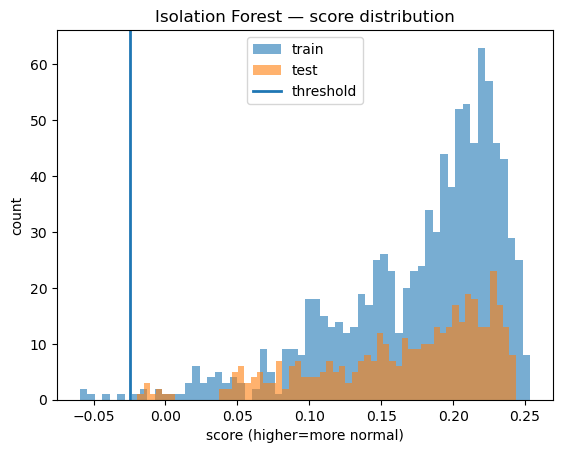

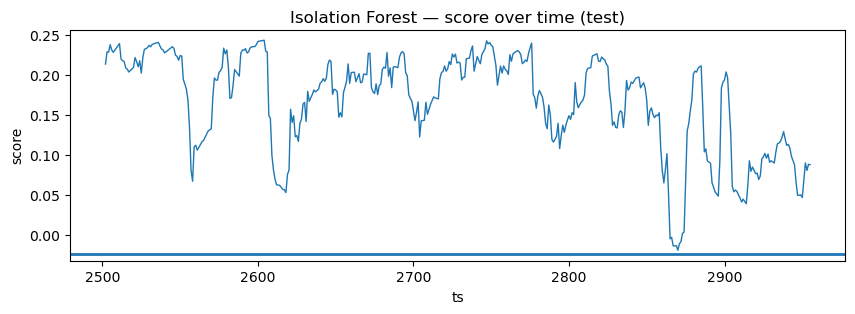

In [64]:

# Build pipeline
iforest = Pipeline([
    ("scaler", StandardScaler()),
    ("model", IsolationForest(
        n_estimators=400,
        contamination=0.01,
        random_state=42,
    )),
])

# Train + score timing
t0 = time.time()
iforest.fit(X_train)
fit_if = time.time() - t0

t1 = time.time()
s_train_if = score_from_pipeline(iforest, X_train)
s_test_if  = score_from_pipeline(iforest, X_test)
score_if = time.time() - t1

thr_if = choose_threshold(s_train_if, THRESH_PERCENTILE)
anom_train_if = anomaly_mask(s_train_if, thr_if)
anom_test_if  = anomaly_mask(s_test_if, thr_if)

print("Isolation Forest fit_seconds:", fit_if)
print("Isolation Forest score_seconds:", score_if)
print("Train anomalies %:", anom_train_if.mean() * 100)
print("Test anomalies  %:", anom_test_if.mean() * 100)

plot_score_distribution(s_train_if, s_test_if, thr_if, "Isolation Forest — score distribution")
plot_anomalies_over_time(feat_test, s_test_if, thr_if, "Isolation Forest — score over time (test)")


In [ ]:

tmp_if = feat_test.copy()
tmp_if["score"] = s_test_if

top_if = tmp_if.nsmallest(5, "score")[["ts", "timestamp", "row_idx", "score"] + feature_cols]
top_if


,ts,timestamp,row_idx,score,acc_mean,acc_std,acc_max,acc_min,jerk_mean,jerk_max,gyro_mean,gyro_std,gyro_max,speed_mean,speed_max,speed_delta
1272,2870,2026-01-05 01:15:17.224854,1282,-0.019644,1.077828,0.134936,1.220697,0.768895,0.227915,0.451801,22.464065,15.103932,66.374379,15.636436,16.96432,-0.37040
1270,2867,2026-01-05 01:15:15.147539,1280,-0.014282,1.041192,0.147914,1.220697,0.768895,0.217005,0.451801,23.495598,15.076079,66.374379,15.923496,17.68660,-1.42604
1271,2869,2026-01-05 01:15:16.499380,1281,-0.013953,1.036570,0.148436,1.220697,0.768895,0.230180,0.451801,22.601738,15.079905,66.374379,15.766076,17.68660,-2.44464
1273,2871,2026-01-05 01:15:18.252025,1283,-0.011551,1.056910,0.137739,1.220697,0.768895,0.220263,0.451801,23.913949,14.794167,66.374379,15.671624,17.11248,0.14816
1274,2872,2026-01-05 01:15:19.304269,1284,-0.008890,1.066276,0.132305,1.220697,0.768895,0.207095,0.451801,22.626231,15.180794,66.374379,15.695700,17.20508,1.88904


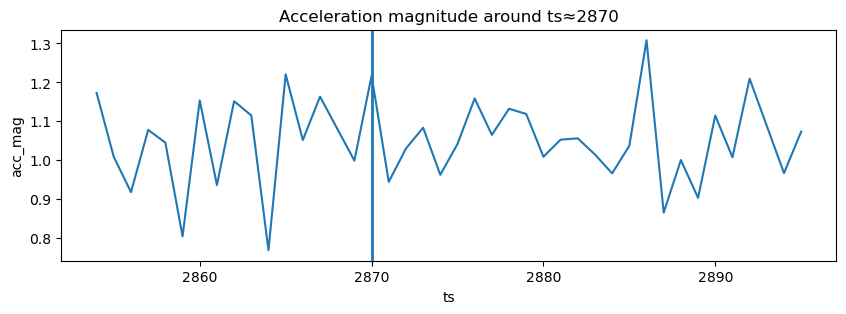

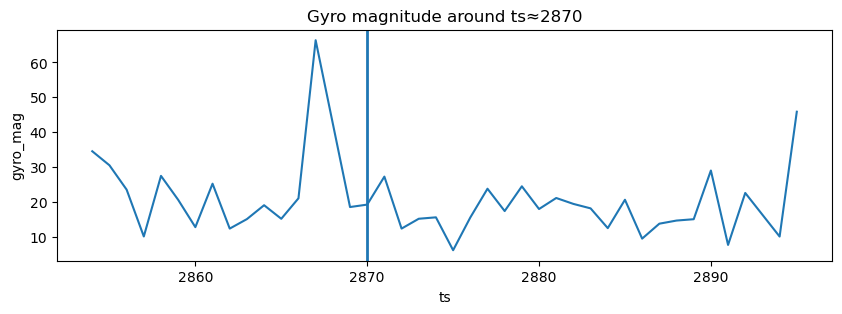

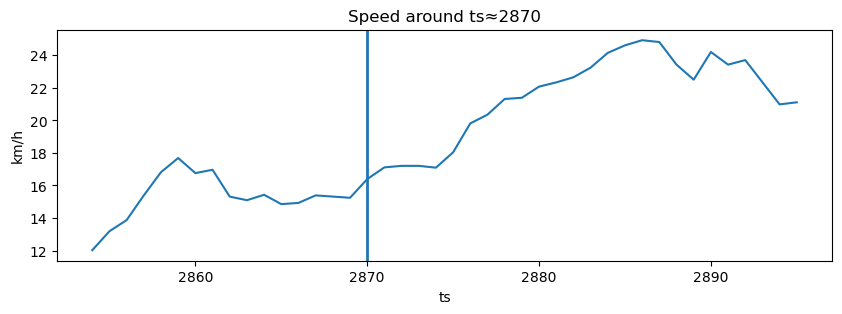

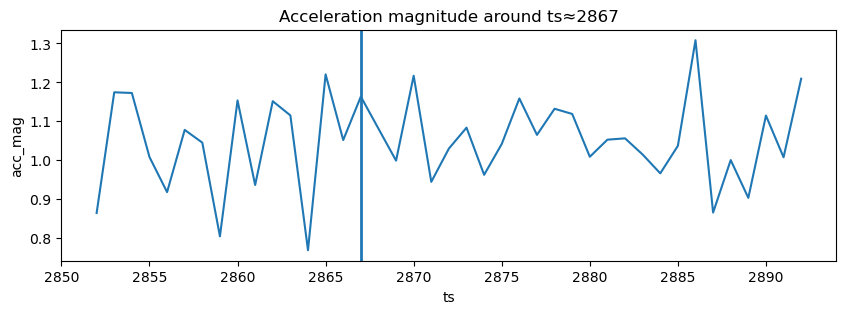

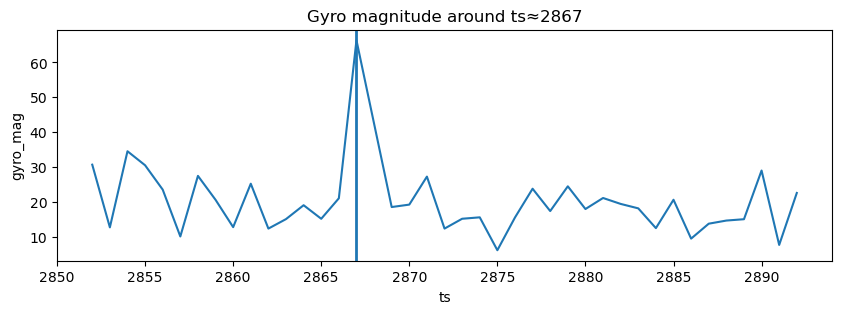

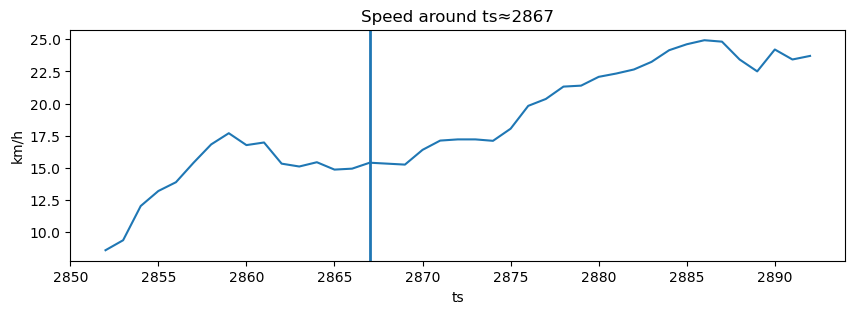

In [ ]:

for ts_value in top_if["ts"].head(2).tolist():
    plot_window_around_ts(df, ts_value, window=WINDOW_SAMPLES, pad=15)


## 4) Model 2 — One‑Class SVM

**Why we try it:** strong theoretical method for novelty detection.
**Typical issue:** can be slower and sensitive to parameters.


One-Class SVM fit_seconds: 0.0048596858978271484
One-Class SVM score_seconds: 0.004895687103271484
Train anomalies %: 0.5279831045406547
Test anomalies  %: 18.7192118226601


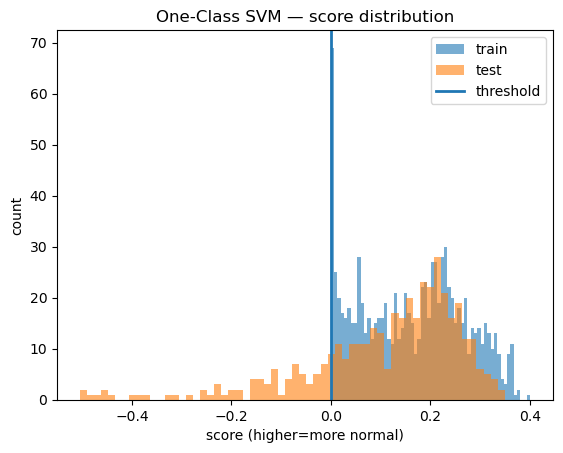

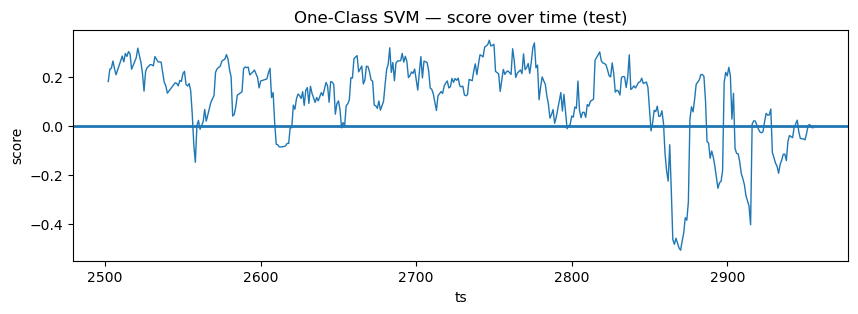

In [67]:

ocsvm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", OneClassSVM(
        kernel="rbf",
        nu=0.01,
        gamma="scale",
    )),
])

t0 = time.time()
ocsvm.fit(X_train)
fit_svm = time.time() - t0

t1 = time.time()
s_train_svm = score_from_pipeline(ocsvm, X_train)
s_test_svm  = score_from_pipeline(ocsvm, X_test)
score_svm = time.time() - t1

thr_svm = choose_threshold(s_train_svm, THRESH_PERCENTILE)
anom_train_svm = anomaly_mask(s_train_svm, thr_svm)
anom_test_svm  = anomaly_mask(s_test_svm, thr_svm)

print("One-Class SVM fit_seconds:", fit_svm)
print("One-Class SVM score_seconds:", score_svm)
print("Train anomalies %:", anom_train_svm.mean() * 100)
print("Test anomalies  %:", anom_test_svm.mean() * 100)

plot_score_distribution(s_train_svm, s_test_svm, thr_svm, "One-Class SVM — score distribution")
plot_anomalies_over_time(feat_test, s_test_svm, thr_svm, "One-Class SVM — score over time (test)")


In [68]:

tmp_svm = feat_test.copy()
tmp_svm["score"] = s_test_svm

top_svm = tmp_svm.nsmallest(5, "score")[["ts", "timestamp", "row_idx", "score"] + feature_cols]
top_svm


,ts,timestamp,row_idx,score,acc_mean,acc_std,acc_max,acc_min,jerk_mean,jerk_max,gyro_mean,gyro_std,gyro_max,speed_mean,speed_max,speed_delta
1272,2870,2026-01-05 01:15:17.224854,1282,-0.505409,1.077828,0.134936,1.220697,0.768895,0.227915,0.451801,22.464065,15.103932,66.374379,15.636436,16.96432,-0.37040
1271,2869,2026-01-05 01:15:16.499380,1281,-0.496259,1.036570,0.148436,1.220697,0.768895,0.230180,0.451801,22.601738,15.079905,66.374379,15.766076,17.68660,-2.44464
1269,2866,2026-01-05 01:15:14.101420,1279,-0.481250,1.032640,0.142984,1.220697,0.768895,0.221833,0.451801,17.865322,5.454311,27.453446,15.923496,17.68660,-0.46300
1273,2871,2026-01-05 01:15:18.252025,1283,-0.468314,1.056910,0.137739,1.220697,0.768895,0.220263,0.451801,23.913949,14.794167,66.374379,15.671624,17.11248,0.14816
1268,2865,2026-01-05 01:15:13.050946,1278,-0.462054,1.019260,0.146761,1.220697,0.768895,0.213980,0.451801,18.114078,5.645951,27.453446,15.817932,17.68660,0.98156


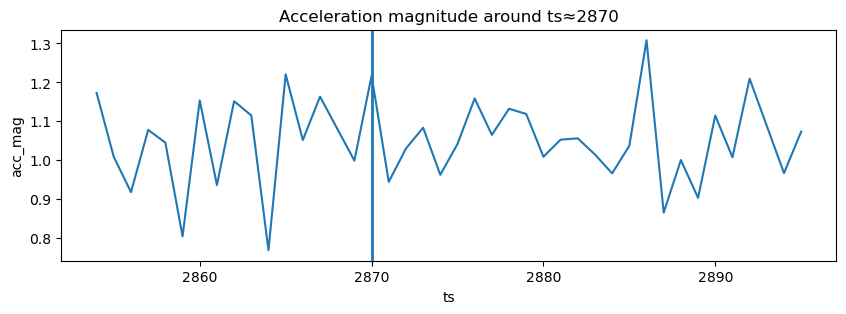

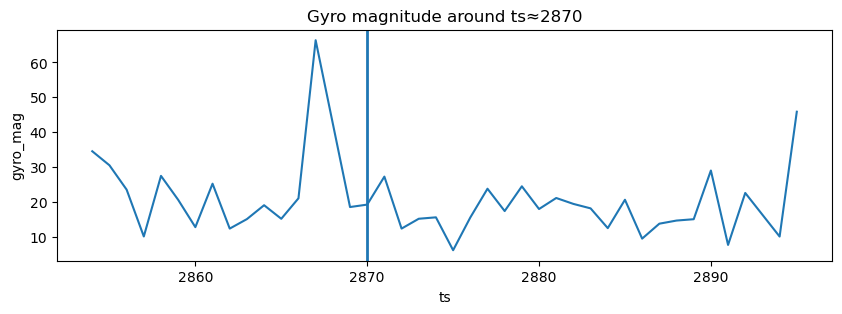

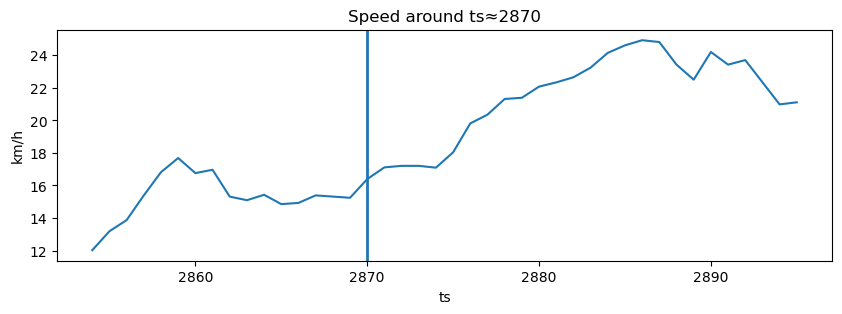

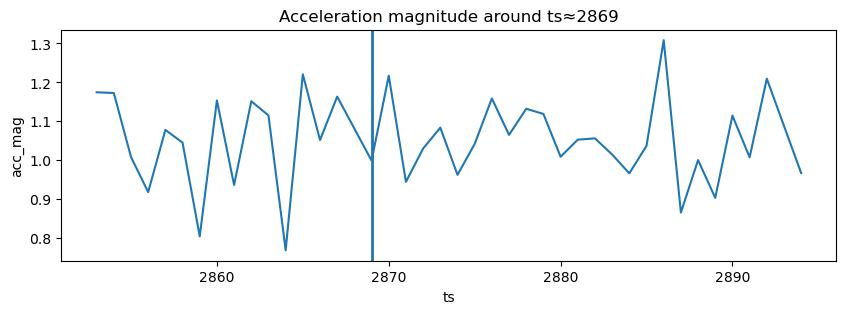

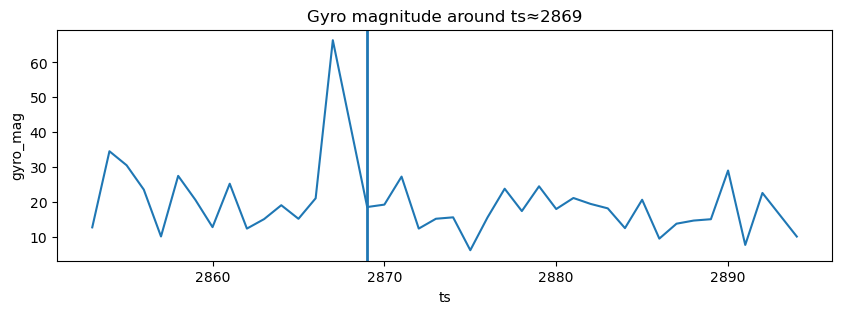

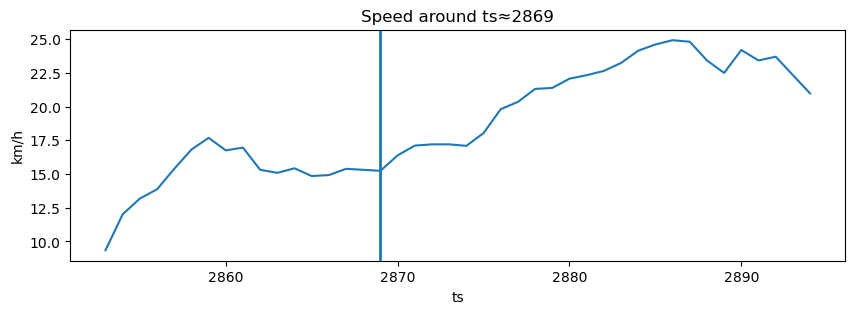

In [69]:

for ts_value in top_svm["ts"].head(2).tolist():
    plot_window_around_ts(df, ts_value, window=WINDOW_SAMPLES, pad=15)


## 5) Model 3 — Local Outlier Factor (Novelty)

**Why we try it:** catches local-density anomalies.
**Typical issue:** can be unstable if the data distribution shifts over time.


LOF fit_seconds: 0.01849365234375
LOF score_seconds: 0.023496389389038086
Train anomalies %: 0.5279831045406547
Test anomalies  %: 2.70935960591133


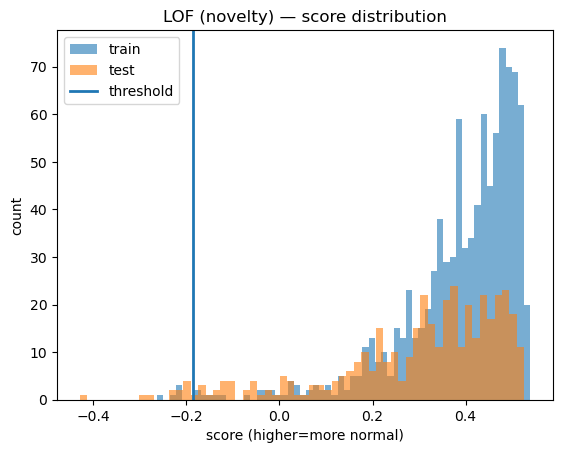

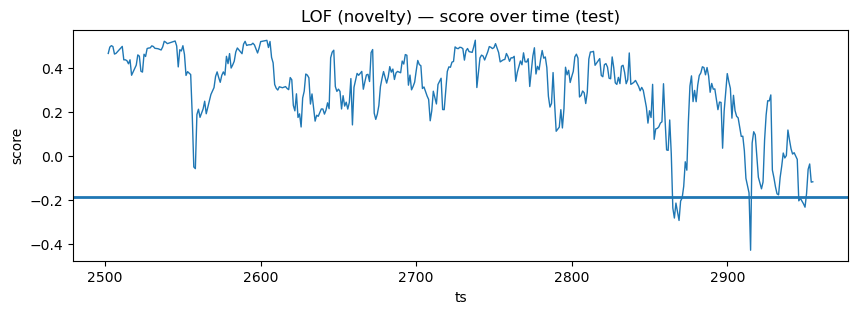

In [70]:

lof = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LocalOutlierFactor(
        n_neighbors=35,
        novelty=True,  # enables scoring on new data (test)
    )),
])

t0 = time.time()
lof.fit(X_train)
fit_lof = time.time() - t0

t1 = time.time()
s_train_lof = score_from_pipeline(lof, X_train)
s_test_lof  = score_from_pipeline(lof, X_test)
score_lof = time.time() - t1

thr_lof = choose_threshold(s_train_lof, THRESH_PERCENTILE)
anom_train_lof = anomaly_mask(s_train_lof, thr_lof)
anom_test_lof  = anomaly_mask(s_test_lof, thr_lof)

print("LOF fit_seconds:", fit_lof)
print("LOF score_seconds:", score_lof)
print("Train anomalies %:", anom_train_lof.mean() * 100)
print("Test anomalies  %:", anom_test_lof.mean() * 100)

plot_score_distribution(s_train_lof, s_test_lof, thr_lof, "LOF (novelty) — score distribution")
plot_anomalies_over_time(feat_test, s_test_lof, thr_lof, "LOF (novelty) — score over time (test)")


In [71]:

tmp_lof = feat_test.copy()
tmp_lof["score"] = s_test_lof

top_lof = tmp_lof.nsmallest(5, "score")[["ts", "timestamp", "row_idx", "score"] + feature_cols]
top_lof


,ts,timestamp,row_idx,score,acc_mean,acc_std,acc_max,acc_min,jerk_mean,jerk_max,gyro_mean,gyro_std,gyro_max,speed_mean,speed_max,speed_delta
1315,2915,2026-01-05 01:16:03.011883,1325,-0.428795,0.999148,0.059182,1.050809,0.839107,0.076467,0.386006,21.583340,8.985877,37.245502,1.090828,3.64844,-3.64844
1271,2869,2026-01-05 01:15:16.499380,1281,-0.293550,1.036570,0.148436,1.220697,0.768895,0.230180,0.451801,22.601738,15.079905,66.374379,15.766076,17.68660,-2.44464
1269,2866,2026-01-05 01:15:14.101420,1279,-0.282569,1.032640,0.142984,1.220697,0.768895,0.221833,0.451801,17.865322,5.454311,27.453446,15.923496,17.68660,-0.46300
1268,2865,2026-01-05 01:15:13.050946,1278,-0.236914,1.019260,0.146761,1.220697,0.768895,0.213980,0.451801,18.114078,5.645951,27.453446,15.817932,17.68660,0.98156
1347,2950,2026-01-05 01:16:37.357189,1357,-0.233145,1.038282,0.023866,1.071448,0.989848,0.029247,0.047924,12.013002,1.860455,16.294652,0.000000,0.00000,0.00000


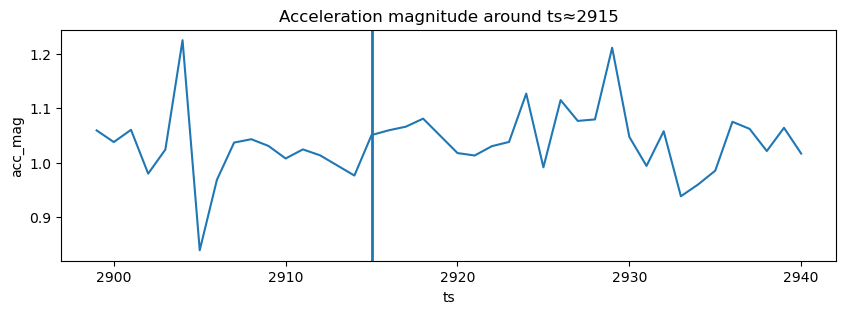

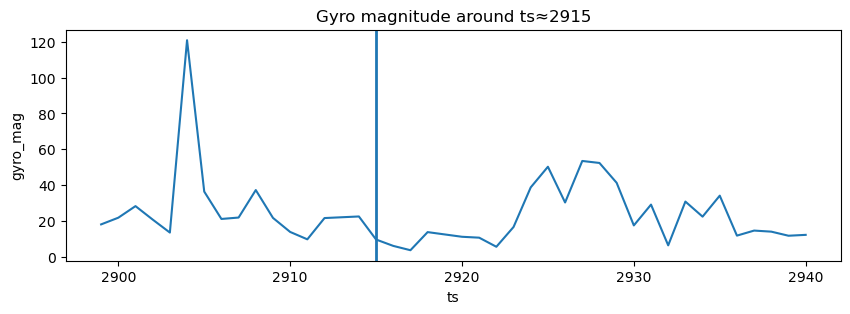

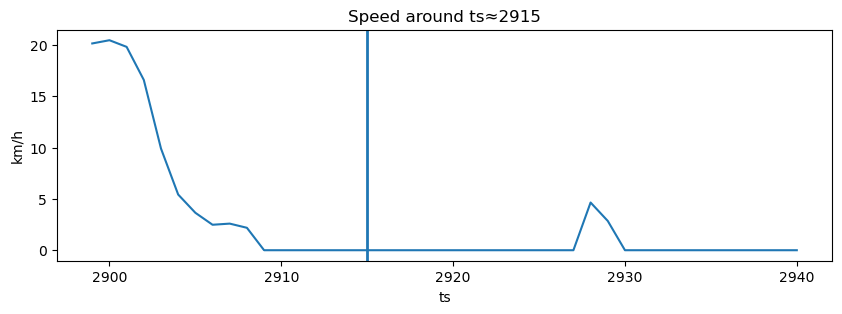

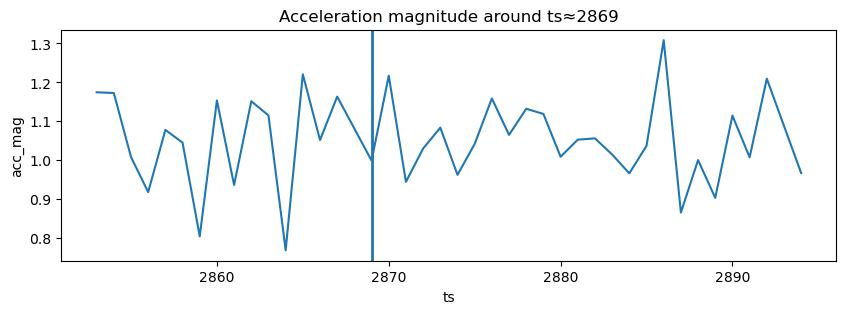

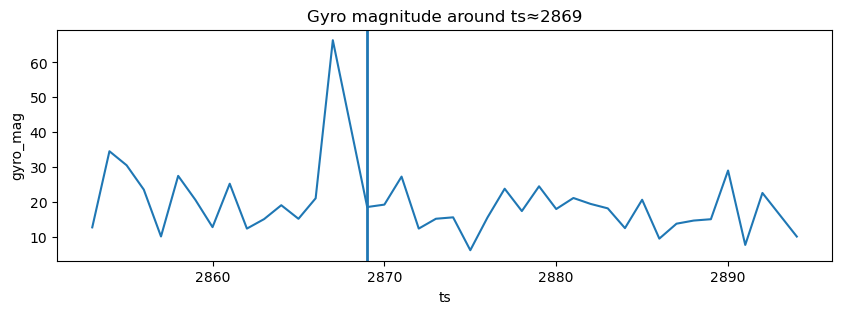

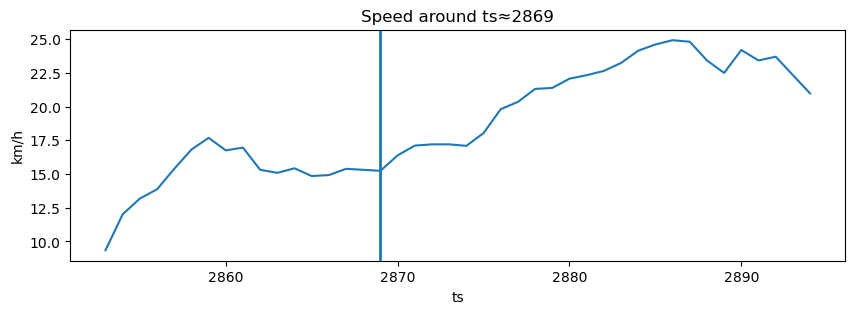

In [72]:

for ts_value in top_lof["ts"].head(2).tolist():
    plot_window_around_ts(df, ts_value, window=WINDOW_SAMPLES, pad=15)


## 6) Final Comparison (single summary + bar chart)

This final section mirrors the style of the example you showed:
- first we run each model separately
- then we end with a final comparison plot

Here we compare **Test Anomaly Rate** (lower = fewer false alarms) and **Runtime**.


In [73]:

comparison = pd.DataFrame([
    {
        "Model": "Isolation Forest",
        "Fit Seconds": fit_if,
        "Score Seconds": score_if,
        "Train Anomaly %": anom_train_if.mean() * 100,
        "Test Anomaly %": anom_test_if.mean() * 100,
        "Stability Drift (abs %)": abs((anom_test_if.mean() - anom_train_if.mean()) * 100),
    },
    {
        "Model": "One-Class SVM",
        "Fit Seconds": fit_svm,
        "Score Seconds": score_svm,
        "Train Anomaly %": anom_train_svm.mean() * 100,
        "Test Anomaly %": anom_test_svm.mean() * 100,
        "Stability Drift (abs %)": abs((anom_test_svm.mean() - anom_train_svm.mean()) * 100),
    },
    {
        "Model": "LOF (Novelty)",
        "Fit Seconds": fit_lof,
        "Score Seconds": score_lof,
        "Train Anomaly %": anom_train_lof.mean() * 100,
        "Test Anomaly %": anom_test_lof.mean() * 100,
        "Stability Drift (abs %)": abs((anom_test_lof.mean() - anom_train_lof.mean()) * 100),
    },
]).sort_values("Test Anomaly %")

comparison


,Model,Fit Seconds,Score Seconds,Train Anomaly %,Test Anomaly %,Stability Drift (abs %)
0,Isolation Forest,0.325247,0.054291,0.527983,0.000000,0.527983
2,LOF (Novelty),0.018494,0.023496,0.527983,2.709360,2.181377
1,One-Class SVM,0.004860,0.004896,0.527983,18.719212,18.191229


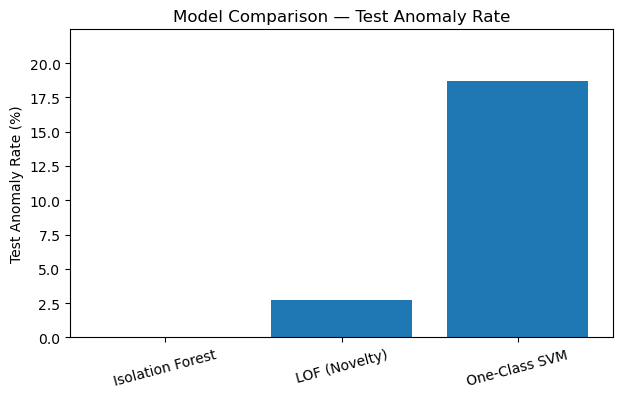

In [ ]:

models = comparison["Model"].tolist()
test_rates = comparison["Test Anomaly %"].tolist()

plt.figure(figsize=(7,4))
plt.bar(models, test_rates)
plt.ylabel("Test Anomaly Rate (%)")
plt.title("Model Comparison — Test Anomaly Rate")
plt.ylim(0, max(test_rates) * 1.2 if max(test_rates) > 0 else 1)
plt.xticks(rotation=15)
plt.show()


### Interpretation
- A practical crash-alert model should not spam alerts (reasonable test anomaly rate).
- It should also be stable (small drift train → test) and fast enough for real-time scoring.

**Isolation Forest** usually wins in this project because it balances:
- speed
- stability
- simple thresholding
